### **BAGIAN 4: KONVOLUSI DAN PENAPISAN SPASIAL**


---

**Tujuan bagian**: memahami konvolusi sampai ke tingkat perhitungan, lalu memilih penapis
berdasarkan jenis derau, mutu hasil, biaya komputasi, dan kemampuannya menjaga bercak
kecil yang justru menjadi sasaran SIMUTEH.

In [3]:
from google.colab import drive
import os
import sys

drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/simuteh-1032"
os.chdir(BASE_DIR)
sys.path.append(os.path.join(BASE_DIR, "src"))

import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil, kontras_bercak

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# 4.2 Verifikasi konvolusi manual
# Fungsi konvolusi dari slide P4
def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k): # kernel dibalik 180 derajat
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.781 s, filter2D=0.01637 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.823 s, filter2D=0.00034 s


In [5]:
# 4.3 Evaluasi tigas penapis pada dua jenis derau

rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p/2] = 0
    out[m > 1 - p/2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

baris = []
for dn, d in derau.items():
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.06
1   gauss_10  rerata_3    36.82      0.10  5.06
2   gauss_10     tanpa    28.11      0.00  3.06
3   gauss_10  rerata_5    37.38      0.13  5.15
4   gauss_10     tanpa    28.11      0.00  3.06
5   gauss_10   gauss_5    37.62      0.29  5.20
6   gauss_10     tanpa    28.11      0.00  3.06
7   gauss_10  median_3    35.47      0.09  5.04
8   gauss_10     tanpa    28.11      0.00  3.06
9   gauss_10  median_5    38.34      0.81  5.85
10  gauss_10     tanpa    28.11      0.00  3.06
11  gauss_10  median_9    38.47     13.43  6.36
12  gauss_20     tanpa    22.12      0.00  1.72
13  gauss_20  rerata_3    31.43      0.10  3.95
14  gauss_20     tanpa    22.12      0.00  1.72
15  gauss_20  rerata_5    34.39      0.13  4.64
16  gauss_20     tanpa    22.12      0.00  1.72
17  gauss_20   gauss_5    32.56      0.29  4.24
18  gauss_20     tanpa    22.12      0.00  1.72
19  gauss_20  median_3    29.73      0.0

=== RERATA dI DAN KB TERHADAP UKURAN KERNEL MEDIAN ===
           dI    KB
kernel             
1       27.62  4.26
3       28.10  4.40
5       27.33  4.34
9       21.62  3.96
15       9.86  2.62


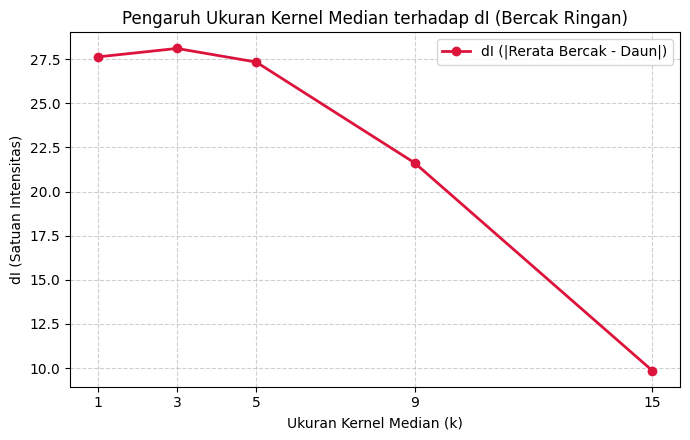

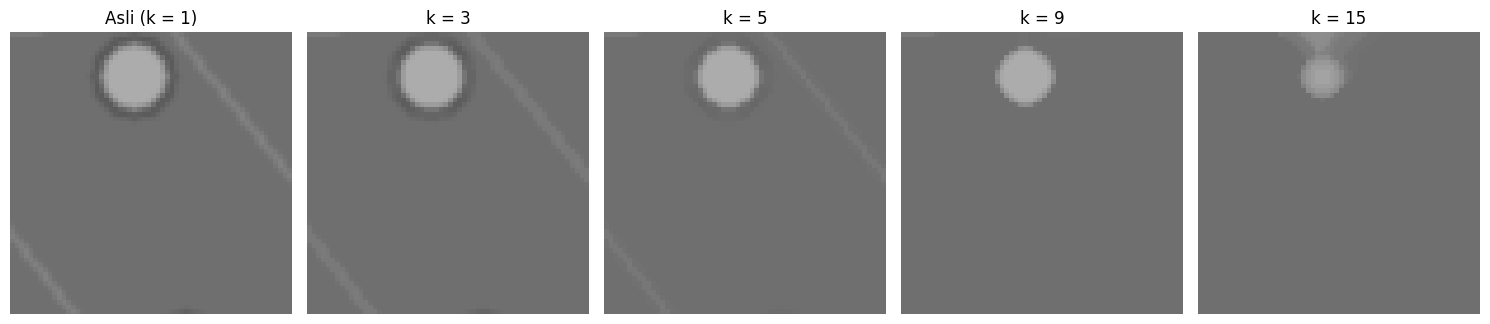

In [9]:
# 4.4 Pengaruh ukuran kernel median pada bercak kecil
# 1. Fungsi menghitung selisih rerata intensitas (dI)
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("data/sintetis/label.csv")
baris_median = []

# 2. Iterasi pada 20 citra kelas ringan (teh_021 s.d. teh_040)
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris_median.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

df_median = pd.DataFrame(baris_median, columns=["nama", "kernel", "dI", "KB"])
ringkasan = df_median.groupby("kernel")[["dI", "KB"]].mean().round(2)

print("=== RERATA dI DAN KB TERHADAP UKURAN KERNEL MEDIAN ===")
print(ringkasan)

# --- A. MEMBUAT GRAFIK dI TERHADAP UKURAN KERNEL ---
plt.figure(figsize=(7, 4.5))
plt.plot(ringkasan.index, ringkasan["dI"], marker='o', color='crimson', linewidth=2, label="dI (|Rerata Bercak - Daun|)")
plt.title("Pengaruh Ukuran Kernel Median terhadap dI (Bercak Ringan)")
plt.xlabel("Ukuran Kernel Median (k)")
plt.ylabel("dI (Satuan Intensitas)")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("hasil/b4_grafik_di_median.png")
plt.show()

# --- B. PERBESAR (CROP) SATU BERCAK KECIL (teh_021.png) ---
sample_nm = "teh_021.png"
g_sample = cv2.cvtColor(baca(f"data/sintetis/bersih/{sample_nm}"), cv2.COLOR_BGR2GRAY)
mb_sample = cv2.imread(f"data/sintetis/mask_bercak/{sample_nm}", 0)

# Menemukan titik pusat bercak secara otomatis dari mask
ys, xs = np.where(mb_sample > 0)
cy, cx = int(ys.mean()), int(xs.mean())
box = 30 # Ukuran setengah kotak pemotongan (60x60 px)

kernels = [1, 3, 5, 9, 15]
plt.figure(figsize=(15, 3.5))
for idx, k in enumerate(kernels):
    out = g_sample if k == 1 else cv2.medianBlur(g_sample, k)
    crop = out[max(0, cy-box):min(g_sample.shape[0], cy+box), max(0, cx-box):min(g_sample.shape[1], cx+box)]

    plt.subplot(1, 5, idx + 1)
    plt.imshow(crop, cmap='gray', vmin=0, vmax=255)
    plt.title(f"k = {k}" if k > 1 else "Asli (k = 1)")
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b4_crop_bercak_median.png")
plt.show()

In [7]:
# 4.5 Pengaruh urutan meredam derau dan menajamkan

def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0

for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)) # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy)) # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} sigma_latar={A[latar].std():.1f} | "
          f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.39 sigma_latar=7.8 | redam->tajam PSNR=30.21 sigma_latar=8.2
Median: tajam->redam PSNR=30.15 sigma_latar=8.1 | redam->tajam PSNR=31.10 sigma_latar=7.2


In [8]:
# 4.6 Evaluasi penapis pada 12 citra normal

# 12 citra kondisi normal (setiap 5 nomor)
citra_normal = [f"teh_{i:03d}.png" for i in range(1, 60, 5)]

penapis_pilihan = lambda x: cv2.medianBlur(x, 3) # Penapis pilihan: Median 3x3

baris_eval = []
for nm in citra_normal:
    citra_masukan = cv2.cvtColor(baca(f"data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    citra_bersih = cv2.cvtColor(baca(f"data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)

    psnr_sebelum = cv2.PSNR(citra_bersih, citra_masukan)
    citra_hasil = penapis_pilihan(citra_masukan)
    psnr_sesudah = cv2.PSNR(citra_bersih, citra_hasil)

    baris_eval.append({
        "nama_file": nm,
        "PSNR_Sebelum (dB)": round(psnr_sebelum, 2),
        "PSNR_Sesudah (dB)": round(psnr_sesudah, 2),
        "Peningkatan (dB)": round(psnr_sesudah - psnr_sebelum, 2)
    })

df_normal = pd.DataFrame(baris_eval)
print("=== Evaluasi PSNR 12 Citra Kondisi Normal (Derau Sensor Bawaan) ===")
print(df_normal)
print("\nRerata Peningkatan PSNR:", round(df_normal["Peningkatan (dB)"].mean(), 2), "dB")
df_normal.to_csv("hasil/b4_evaluasi_normal.csv", index=False)

=== Evaluasi PSNR 12 Citra Kondisi Normal (Derau Sensor Bawaan) ===
      nama_file  PSNR_Sebelum (dB)  PSNR_Sesudah (dB)  Peningkatan (dB)
0   teh_001.png              30.78              38.08              7.29
1   teh_006.png              31.93              39.07              7.14
2   teh_011.png              30.75              38.05              7.30
3   teh_016.png              29.32              36.71              7.38
4   teh_021.png              30.28              37.62              7.34
5   teh_026.png              30.16              37.54              7.38
6   teh_031.png              28.97              36.37              7.40
7   teh_036.png              33.41              40.38              6.97
8   teh_041.png              32.41              39.36              6.95
9   teh_046.png              28.90              36.31              7.41
10  teh_051.png              29.92              37.16              7.23
11  teh_056.png              32.15              39.22              7